# SpA-Sentinel: AI agent demo for ankylosing spondylitis (axSpA)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Muthuuk/SpA-Sentinel/blob/main/notebooks/SpA_Sentinel_Demo.ipynb)

Companion demo for the ABH 2027 paper *AI Agents for Predicting Ankylosing Spondylitis Flares and Extra-Spinal Spread*.

**Research and teaching demonstrator only. All data are synthetic. This is not a medical device and must not be used for decisions about real patients.**

The notebook walks through the paper in order:
1. Generate (or load) the synthetic datasets.
2. Train and evaluate the four models: M1 flare forecaster, M2 flare-or-infection scorer, M3 organ-spread risk, M4 drug response with SHAP.
3. Run the agent on the worked example from the paper (Patient A).
4. Print an inflammation alert card.
5. Re-run the ROI model and change its assumptions.

In [1]:
# Setup: works in Google Colab and locally
import os, sys
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Muthuuk/SpA-Sentinel.git"   # change if the repository lives elsewhere
if IN_COLAB:
    !pip -q install xgboost lifelines shap
    if not os.path.exists("SpA-Sentinel"):
        !git clone -q {REPO_URL}
    os.chdir("SpA-Sentinel")
elif not os.path.exists("spa_sentinel") and os.path.exists("../spa_sentinel"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from spa_sentinel import DISCLAIMER
print(DISCLAIMER)

RESEARCH DEMONSTRATOR ONLY - synthetic data - not a medical device - not for clinical use.


## 1. Synthetic datasets

No real patient data are used. `spa_sentinel/data_gen.py` simulates five linked tables with clinically plausible relationships taken from the literature in the paper (for example, CRP rises in both flares and infections; higher CRP and lower BMI favour TNF-inhibitor response). The effect sizes are illustrative. Set `REGENERATE = True` to rebuild the CSV files in `data/` with a new seed.

In [2]:
from spa_sentinel.data_gen import generate_all
REGENERATE = False
names = ["patients", "weekly", "crp_episodes", "organ_spread", "tnfi_starts"]
if REGENERATE or not all(os.path.exists(f"data/{n}.csv") for n in names):
    tables = generate_all("data", seed=7)
else:
    tables = {n: pd.read_csv(f"data/{n}.csv") for n in names}
for n, df in tables.items():
    print(f"{n:13s} {df.shape[0]:6d} rows x {df.shape[1]:2d} columns")
tables["patients"].head()

patients        1200 rows x 14 columns
weekly         50178 rows x 13 columns
crp_episodes    6000 rows x 15 columns
organ_spread    1200 rows x 13 columns
tnfi_starts     1500 rows x 10 columns


,patient_id,sex,age,disease_duration_y,hla_b27,bmi,ibd,uveitis_history,psoriasis,egfr,crp_remission,crp_flare_typical,low_crp_phenotype,biologic
0,P0000,M,61.0,9.5,1,25.1,1,0,1,99.0,2.8,15.9,0,TNFi
1,P0001,F,18.0,8.9,0,29.4,0,0,0,59.0,2.5,3.8,1,none
2,P0002,F,38.0,12.0,1,26.7,0,0,0,88.0,6.0,8.6,1,TNFi
3,P0003,M,45.0,14.8,1,24.9,0,0,1,96.0,5.5,48.3,0,none
4,P0004,M,38.0,6.7,1,25.6,0,0,0,102.0,12.1,72.8,0,none


Each person has a **personal CRP baseline** (`crp_remission`) and a typical flare value (`crp_flare_typical`). About a third have a *low-CRP phenotype*, whose CRP barely moves during flares: this is the "normal blood test during active disease" problem described in Section 2.1 of the paper.

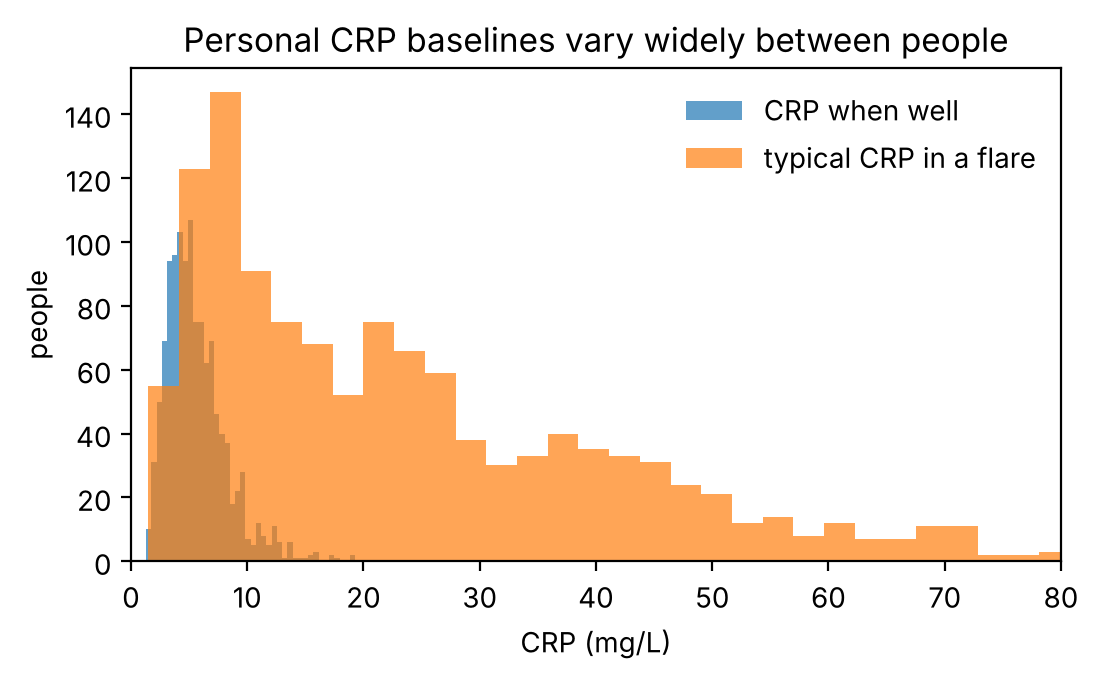

In [3]:
p = tables["patients"]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(p["crp_remission"], bins=40, alpha=0.7, label="CRP when well")
ax.hist(p["crp_flare_typical"], bins=40, alpha=0.7, label="typical CRP in a flare")
ax.set_xlabel("CRP (mg/L)"); ax.set_ylabel("people"); ax.set_xlim(0, 80); ax.legend(frameon=False)
ax.set_title("Personal CRP baselines vary widely between people"); plt.show()

## 2. Train and evaluate the four models
Test sets are held out by patient, so no person appears in both training and testing.

In [4]:
from spa_sentinel.models import train_all, calibration_table
T = train_all(tables, seed=0)
summary = pd.DataFrame([
    ["M1 flare in next 14 days", "AUROC", T["m1_metrics"]["auroc"]],
    ["M2 infection vs flare", "AUROC", T["m2_metrics"]["auroc"]],
    ["M2 at safety threshold", "sensitivity for infection", T["m2_metrics"]["sensitivity_infection"]],
    ["M2 at safety threshold", "specificity", T["m2_metrics"]["specificity"]],
    ["M3 new IBD (3 years)", "C-index", T["m3"]["ibd"]["c_index"]],
    ["M3 kidney involvement (3 years)", "C-index", T["m3"]["kidney"]["c_index"]],
    ["M4 TNFi response (XGBoost)", "AUROC", T["m4_metrics"]["auroc_xgb"]],
    ["M4 TNFi response (logistic)", "AUROC", T["m4_metrics"]["auroc_logistic"]],
], columns=["model", "metric", "value"])
summary["value"] = summary["value"].round(3); summary

,model,metric,value
0,M1 flare in next 14 days,AUROC,0.700
1,M2 infection vs flare,AUROC,0.918
2,M2 at safety threshold,sensitivity for infection,0.993
3,M2 at safety threshold,specificity,0.235
4,M3 new IBD (3 years),C-index,0.749
5,M3 kidney involvement (3 years),C-index,0.770
6,M4 TNFi response (XGBoost),AUROC,0.699
7,M4 TNFi response (logistic),AUROC,0.686


**Reading the results.** M1 and M4 reach AUROC values around 0.70, similar to published work (Wang et al., 2022, reported accuracy of about 0.71 to 0.76 for TNF-inhibitor response). M2 separates infection from flare well overall, but look at the trade-off below: if we insist on catching about 98% of infections, the model can only "clear" a minority of flares. That is why the agent never says "no antibiotics"; it says "take cultures first".

In [5]:
from spa_sentinel.models import train_m2
rows = []
for target in (0.90, 0.95, 0.98):
    _, thr, m, _ = train_m2(tables["crp_episodes"], target_sensitivity=target, seed=0)
    rows.append([target, round(thr, 3), round(m["sensitivity_infection"], 3), round(m["specificity"], 3)])
pd.DataFrame(rows, columns=["target sensitivity", "threshold", "test sensitivity", "test specificity"])

,target sensitivity,threshold,test sensitivity,test specificity
0,0.90,0.144,0.902,0.727
1,0.95,0.054,0.966,0.480
2,0.98,0.019,0.993,0.235


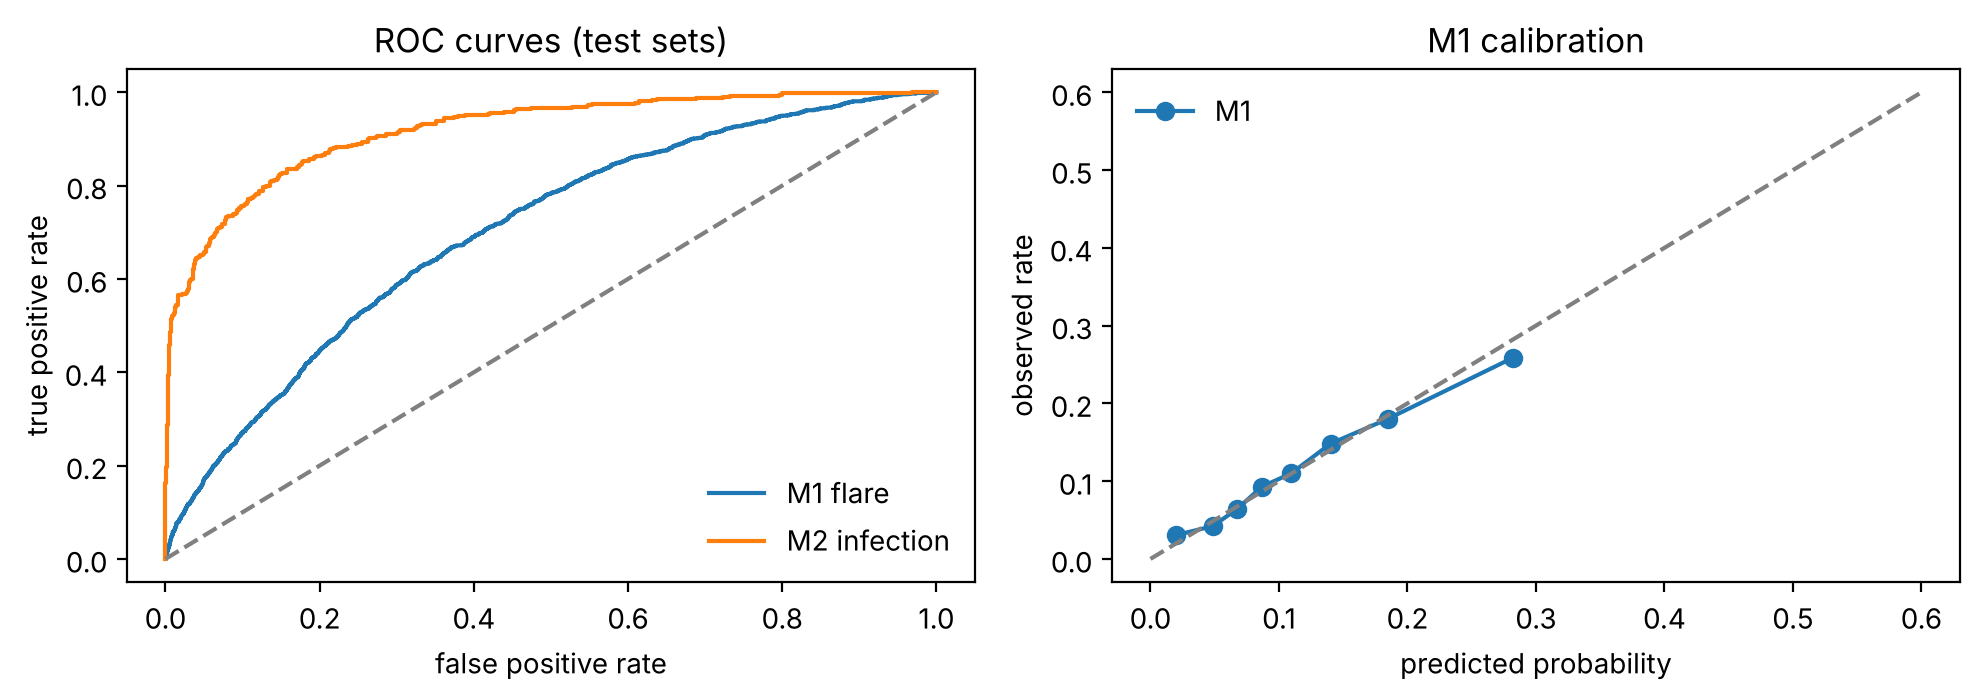

In [6]:
from sklearn.metrics import roc_curve
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for name, (y, pr) in [("M1 flare", T["m1_eval"]), ("M2 infection", T["m2_eval"])]:
    fpr, tpr, _ = roc_curve(y, pr); axes[0].plot(fpr, tpr, label=name)
axes[0].plot([0, 1], [0, 1], ls="--", c="grey"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
axes[0].legend(frameon=False); axes[0].set_title("ROC curves (test sets)")
y, pr = T["m1_eval"]; ct = calibration_table(y, pr, bins=8)
axes[1].plot(ct["mean_predicted"], ct["observed_rate"], "o-", label="M1"); axes[1].plot([0, .6], [0, .6], ls="--", c="grey")
axes[1].set_xlabel("predicted probability"); axes[1].set_ylabel("observed rate"); axes[1].set_title("M1 calibration"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

### M3: Cox models for spread to other organs
Hazard ratios above 1 raise risk. In the synthetic data, repeated antibiotic courses and high faecal calprotectin raise the risk of new IBD, matching the direction reported by Nguyen et al. (2020) and Cypers et al. (2016).

In [7]:
T["m3"]["ibd"]["model"].summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3)

,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
faecal_calprotectin_log,1.996,1.507,2.644,0.000
gut_symptoms,1.407,0.875,2.263,0.159
antibiotic_courses_2y,1.093,0.943,1.266,0.237
on_il17i,1.997,0.629,6.340,0.241
hla_b27,0.884,0.531,1.472,0.635


### M4: drug response with SHAP explanations

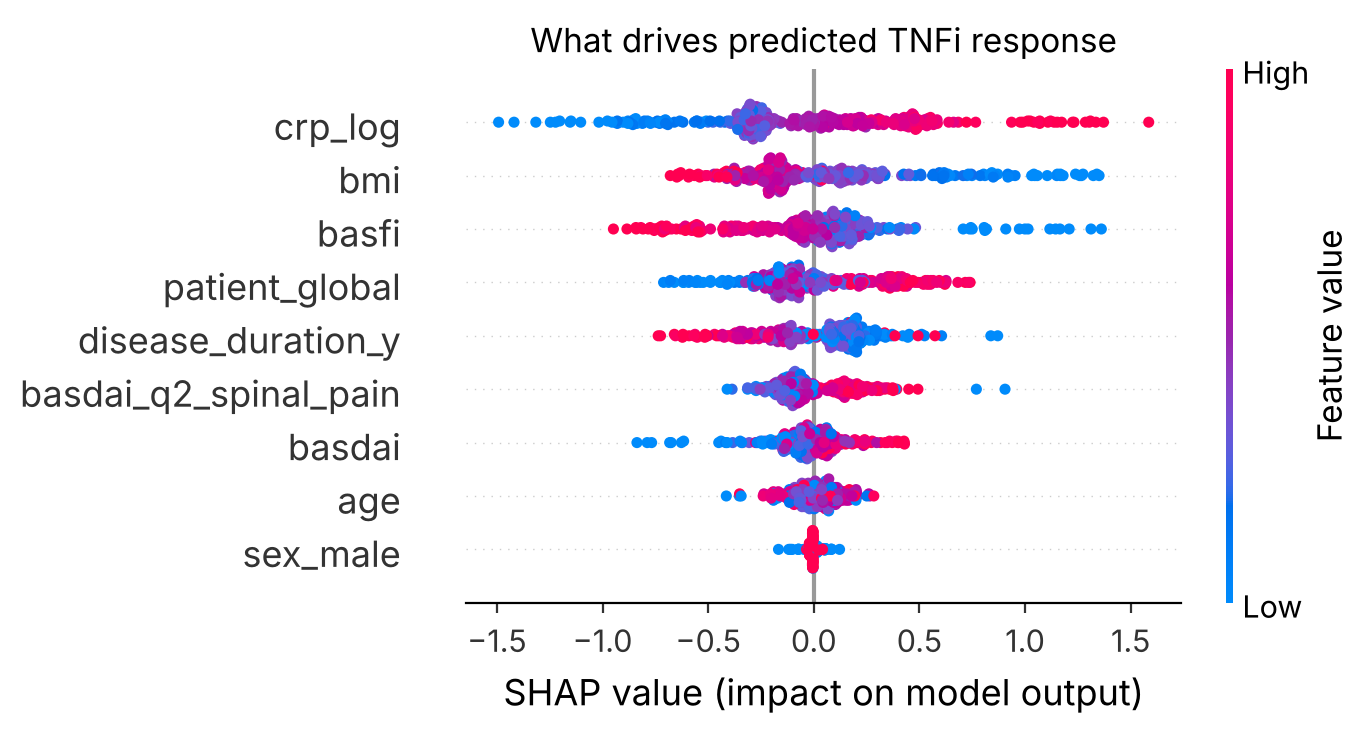

In [8]:
import shap
X4 = T["m4_test"]; from spa_sentinel.models import prep_m4, M4_FEATURES
sv = shap.TreeExplainer(T["m4"]).shap_values(prep_m4(X4)[M4_FEATURES])
shap.summary_plot(sv, prep_m4(X4)[M4_FEATURES], show=False, plot_size=(7, 3.6)); plt.title("What drives predicted TNFi response"); plt.show()

## 3. The agent: worked example from the paper (Patient A)
Patient A is fictional: 41, AS for nine years, HLA-B27 positive, on adalimumab (a TNF inhibitor). His CRP is usually about 6 mg/L when well and 32 mg/L in flares. He sees his GP with urinary frequency and pelvic pain; CRP 36 mg/L, temperature 37.1 °C, urine dipstick shows blood but no nitrites.

In [9]:
from spa_sentinel.agent import SpASentinel, explain_with_llm
agent = SpASentinel(T)
patient_a = dict(patient_id="Patient A", age=41, biologic="TNFi", crp_remission=6, crp_flare_typical=32,
                 ibd=0, uveitis_history=0, egfr=88, tb_screened=True)
episode = dict(crp=36, temp_c=37.1, heart_rate=82, wbc=8.6, resp_rate=16, systolic_bp=124, site="urinary",
               urine_nitrites=0, urine_leukocytes=0, urine_blood=1, basdai_rise=1.6, inflammatory_back_pain=1)
organ = dict(faecal_calprotectin=70, gut_symptoms=0, antibiotic_courses_2y=3, on_il17i=0, hla_b27=1,
             urine_pcr=34, nsaid_years=8, egfr=88)
tnfi_row = dict(age=41, sex_male=1, bmi=29, crp=36, basdai=5.8, basdai_q2_spinal_pain=6.5, basfi=4.2,
                disease_duration_y=9, patient_global=6.0)
report = agent.assess_raised_crp(patient_a, episode, organ)
drugs = agent.drug_options(patient_a, tnfi_row)
print(agent.summary(report, drugs))

RESEARCH DEMONSTRATOR ONLY - synthetic data - not a medical device - not for clinical use.

SpA-Sentinel summary for Patient A (CRP 36 mg/L)
Usual CRP: 6 mg/L in remission, about 32 mg/L in flares.
This CRP is within this patient's usual flare range.
Model M2: infection probability 0.14 (safety threshold 0.02).
Overall: UNCERTAIN - CRP is in this patient's usual flare range, but infection is not excluded: take cultures before any antibiotic.

Safety rules:
  [WARN] Patient takes a biologic or targeted drug (TNFi): higher infection risk; take cultures today and review the same day.
  [WARN] Blood or protein in the urine: check urine protein:creatinine ratio and eGFR; consider kidney involvement (IgA nephropathy, amyloidosis, drug effect).
  [INFO] If no sepsis signs, look for a source (urine or blood culture, chest examination) before starting antibiotics, as stewardship guidance recommends.

12-month risk (M3): ibd 3.1%, kidney 4.4%

Drug choice checks:
  M4: probability of TNF-inhibit

Now the same patient with **signs of sepsis** (temperature 38.9 °C, heart rate 118). The hard safety rule overrides the model, whatever probability M2 gives.

In [10]:
septic = dict(episode, temp_c=38.9, heart_rate=118, wbc=15.8)
print(agent.summary(agent.assess_raised_crp(patient_a, septic)))

RESEARCH DEMONSTRATOR ONLY - synthetic data - not a medical device - not for clinical use.

SpA-Sentinel summary for Patient A (CRP 36 mg/L)
Usual CRP: 6 mg/L in remission, about 32 mg/L in flares.
This CRP is within this patient's usual flare range.
Model M2: infection probability 0.94 (safety threshold 0.02).
Overall: POSSIBLE SEPSIS - follow sepsis pathway (rules override the model).

Safety rules:
  [STOP] Possible sepsis: follow the local sepsis pathway now. Do not delay antibiotics.
  [WARN] Patient takes a biologic or targeted drug (TNFi): higher infection risk; take cultures today and review the same day.
  [WARN] Blood or protein in the urine: check urine protein:creatinine ratio and eGFR; consider kidney involvement (IgA nephropathy, amyloidosis, drug effect).

Any change to treatment needs sign-off by the rheumatology team.


Optional: if you set an `ANTHROPIC_API_KEY` (in Colab: *Secrets*), the template summary can be reworded in plain English by a language model. It only rewords; the rule outcomes and numbers stay fixed.

In [11]:
print(explain_with_llm(agent.summary(report, drugs)))

(No ANTHROPIC_API_KEY set - template summary shown above is used.)


## 4. Inflammation alert card

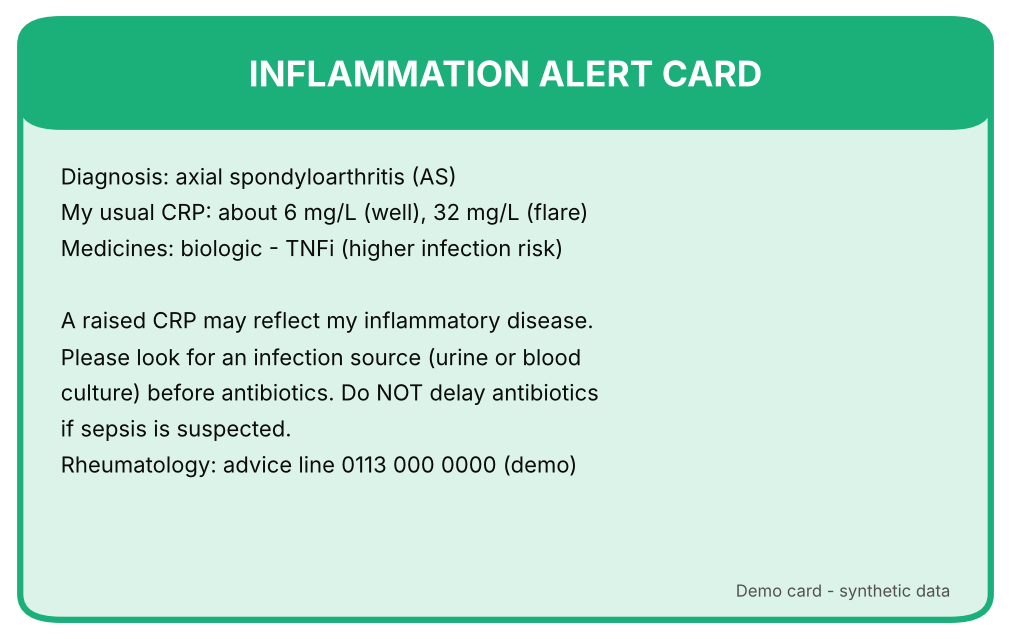

In [12]:
from spa_sentinel.card import make_card
from IPython.display import Image, display
display(Image(make_card(patient_a, contact="advice line 0113 000 0000 (demo)", path="alert_card.png"), width=480))

## 5. Return on investment
These are the illustrative assumptions from Table 5 of the paper. Change any value and re-run to test your own service.

In [13]:
from spa_sentinel.roi import run, Assumptions
single, network = run(Assumptions()), run(Assumptions(trusts_sharing=3))
print({k: round(v) for k, v in single["items"].items()})
print(f"Annual NHS benefit: £{single['annual_benefit']:,.0f}")
for name, r in [("single trust", single), ("three-trust network", network)]:
    print(f"{name:20s} 5-year ROI {r['roi']:.0%}, break-even year {r['breakeven_year']}")
plt.figure(figsize=(5, 3.2))
for name, r in [("Single trust", single), ("Three-trust network", network)]:
    plt.plot(range(1, 6), [v / 1000 for v in r["cumulative_net"]], "o-", label=name)
plt.axhline(0, c="grey", lw=0.8); plt.xlabel("Year"); plt.ylabel("Cumulative net benefit (£k)"); plt.legend(frameon=False); plt.show()

{'antibiotic courses avoided': 9000, 'admissions avoided': 46080, 'A&E visits avoided': 10800, 'ineffective biologic courses avoided': 17500, 'clinician time released': 26400}
Annual NHS benefit: £109,780
single trust         5-year ROI 9%, break-even year 5
three-trust network  5-year ROI 47%, break-even year 3


## Limitations
* All data are synthetic; the metrics show that the pipeline works, not how it would perform on real patients.
* Thresholds and rules are illustrative and must be set and signed off by a clinical safety officer.
* Real deployment needs retrospective validation on local records, silent-mode testing and a supervised pilot (paper, Section 5.1).